# 22 v2 — QAOA exact/shots trên một bộ quy chiếu

**Input duy nhất: `a3_dev_n5`, 5 task + 3 host, 25 qubit.** Giữ cố định CPU/RAM, thứ tự biến, domain-wall, penalty 4, X mixer và max_abs scaling. Chỉ thay cách đánh giá năng lượng khi huấn luyện.

Mục tiêu: kiểm tra việc bỏ nhiễu lấy mẫu có cải thiện bộ góc QAOA trên đúng input này không. `Exact` là kỳ vọng năng lượng của trạng thái QAOA hiện tại; COBYLA vẫn tìm góc, không nhận đáp án placement để chọn góc.

Bản v2 thay thế bản hai-host chưa chạy. Không gộp dữ liệu cũ. Đọc `N22_README_FIRST.md`; notebook bàn giao để trống output. Kết quả QA không phải kết quả thí nghiệm chính.

## 1. Môi trường và resume

Lần đầu giữ `RESUME_DIR=None`. Nếu đã chạy một phần v2, nhập đúng thư mục campaign cũ. `MAX_NEW_RUNS=1` cho phép chia nhỏ phiên chạy mà không đổi protocol. `PREPARE_ONLY=True` chỉ hiệu chuẩn và đo chi phí, chưa huấn luyện; muốn chạy tiếp phải resume campaign vừa tạo.

Mặc định Run All hiệu chuẩn rồi chạy toàn bộ 12 lượt. Chi phí ở 25 qubit có thể kéo dài nhiều giờ; thời gian ước lượng được in trước huấn luyện. Tránh máy sleep và đóng ứng dụng nặng.

In [1]:
from pathlib import Path
import json
import subprocess
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p/'src/shot_noise_campaign.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook trong repo sau khi chép đầy đủ gói Notebook 22.')
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.shot_noise_campaign import (PROTOCOL, load_json, identity, make_plan,
    create_campaign, prepare_campaign, run_campaign, summarize, export_campaign)
from src.three_host_encoding import build_three_host_qubo, three_host_reference
from src.qaoa_experiment import qubo_fingerprint

RESUME_DIR = None  # Ví dụ: r"D:\repo\data\reference_results\phase4n_shot_noise\noise_..."
MAX_NEW_RUNS = None  # Hoặc 1 để chia nhỏ; phải resume đúng campaign ở lần sau.
PREPARE_ONLY = False  # True: chỉ hiệu chuẩn, đo thời gian; lần sau phải resume.
RETRY_FAILED = False  # Chỉ đổi sau khi xem traceback và xử lý nguyên nhân.

print('Python:', sys.executable)
print('Repo:', ROOT)


Python: c:\Users\Khiem\anaconda3\envs\nt409-khiem\python.exe
Repo: c:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement


## 2. Xác nhận input và thiết kế cố định

Input: t0–t3 mỗi task (CPU=1,RAM=1); t4 (1,2). Host h0 (2,2), h1 (3,3), h2 (3,3). Không đổi demand/capacity giữa các lượt.

**12 lượt = 1 input × p=1,2 × (1 exact + 5 shots)**. Năm seed shots 300–304 chỉ đổi phép lấy mẫu, không phải multistart. Trần 200 lần đánh giá/lượt, rhobeg=1, tol=1e-4; có thể dừng sớm khác nhau. Penalty của domain-wall và capacity đều bằng 4 theo mô hình ba host đã có, không dùng penalty 3 của bản hai-host.

Vét cạn 243 cách gán task→host chỉ để chứng nhận ground truth: có 8 cách hợp lệ dùng hai host và 82 cách dùng ba host. Tối ưu là hai host. Các tỷ lệ từ phép gán này khác phân phối trên toàn bộ bit domain-wall/y/slack.

In [2]:
protocol = load_json(ROOT/PROTOCOL)
ident = identity(ROOT, protocol)
model_rows = []
for item in protocol['instances']:
    bundle = build_three_host_qubo(ident['inputs'][item['instance_id']])
    fingerprint = qubo_fingerprint(bundle)
    if fingerprint != item['qubo_sha256']:
        raise ValueError('QUBO khác mô hình ba-host đã cố định: '+item['instance_id'])
    model_rows.append({'instance': item['instance_id'],
                       'qubits': bundle['qubo'].get_num_vars(), 'qubo_sha256': fingerprint})
display(pd.DataFrame(model_rows))
reference = three_host_reference(bundle)
display(pd.DataFrame(ident['inputs'][protocol['instances'][0]['instance_id']]['tasks']))
display(pd.DataFrame(ident['inputs'][protocol['instances'][0]['instance_id']]['hosts']))
print('Ground truth task→host:', reference['placement_histogram'])
plan = make_plan(protocol)
display(pd.DataFrame([{'id': x['id'], 'mode': x['mode'], 'p': x['p'],
                      'seed': x['config']['seed'], 'initial_point': x['config']['initial_point'],
                      'max_evaluations': x['config']['maxiter']} for x in plan]))
print('Số lượt:', len(plan), '| software_validation:', protocol['software_validation'])
print('Runtime:', json.dumps(ident['runtime'], ensure_ascii=False, indent=2))


,instance,qubits,qubo_sha256
0,a3_dev_n5,25,8fa77f91e277724277e5aaf4c1a29b5cec345e91e3660f...


,id,cpu,ram
0,t0,1,1
1,t1,1,1
2,t2,1,1
3,t3,1,1
4,t4,1,2


,id,cpu,ram
0,h0,2,2
1,h1,3,3
2,h2,3,3


Ground truth task→host: {'2': 8, '3': 82}


,id,mode,p,seed,initial_point,max_evaluations
0,a3_dev_n5__p1__exact_0,exact,1,0,"[0.3, 1.0]",200
1,a3_dev_n5__p1__shots_1,shots,1,300,"[0.3, 1.0]",200
2,a3_dev_n5__p1__shots_2,shots,1,301,"[0.3, 1.0]",200
3,a3_dev_n5__p1__shots_3,shots,1,302,"[0.3, 1.0]",200
4,a3_dev_n5__p1__shots_4,shots,1,303,"[0.3, 1.0]",200
5,a3_dev_n5__p1__shots_5,shots,1,304,"[0.3, 1.0]",200
6,a3_dev_n5__p2__exact_0,exact,2,0,"[0.3, 0.0, 1.0, 0.0]",200
7,a3_dev_n5__p2__shots_1,shots,2,300,"[0.3, 0.0, 1.0, 0.0]",200
8,a3_dev_n5__p2__shots_2,shots,2,301,"[0.3, 0.0, 1.0, 0.0]",200
9,a3_dev_n5__p2__shots_3,shots,2,302,"[0.3, 0.0, 1.0, 0.0]",200


Số lượt: 12 | software_validation: False
Runtime: {
  "python_version": "3.12.14",
  "platform": "Windows-11-10.0.26200-SP0",
  "numpy_version": "2.5.3",
  "scipy_version": "1.18.1",
  "qiskit_version": "2.5.2",
  "qiskit_optimization_version": "0.7.0",
  "qiskit_aer_version": "0.17.2"
}


## 3. Kiểm tra phần mềm bằng đúng Python của kernel

Kiểm tra năng lượng/bit order bằng tham chiếu độc lập, xác suất Aer so với Statevector, hai nhánh huấn luyện, seed, lưu/resume và phát hiện dữ liệu hỏng. Chỉ dùng campaign nhỏ trong thư mục tạm, tự xóa sau test. Nếu lỗi, dừng và giữ traceback.


In [4]:
check = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests',
                        '-p', 'test_shot_noise*.py'], cwd=ROOT, text=True,
                       capture_output=True)
print(check.stdout)
print(check.stderr)
check.check_returncode()



..c:\Users\Khiem\anaconda3\envs\nt409-khiem\Lib\site-packages\qiskit\circuit\library\n_local\evolved_operator_ansatz.py:324: DeprecationWarning: The class ``qiskit.circuit.library.n_local.n_local.NLocal`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. This applies to NLocal subclasses too. Use the corresponding function from the module qiskit.circuit.library.n_local instead.
  super().__init__(
c:\Users\Khiem\anaconda3\envs\nt409-khiem\Lib\site-packages\qiskit\circuit\library\n_local\n_local.py:379: DeprecationWarning: The class ``qiskit.circuit.library.blueprintcircuit.BlueprintCircuit`` is deprecated as of Qiskit 2.1. It will be removed in Qiskit 3.0. There is no direct replacement other than the QuantumCircuit class.
  super().__init__(name=name)
............
----------------------------------------------------------------------
Ran 14 tests in 2.938s

OK



## 4. Tạo hoặc mở campaign v2

Ghi lại đường dẫn để resume. Input, protocol, nguồn và runtime được khóa bằng checksum. Giữ nguyên môi trường khi resume. Không resume campaign v1 hai-host. Mỗi lần `RESUME_DIR=None` tạo một campaign riêng.

In [5]:
CAMPAIGN_DIR = create_campaign(ROOT, output=RESUME_DIR, protocol=protocol)
print('CAMPAIGN_DIR =', str(CAMPAIGN_DIR))
print('Lần sau đặt RESUME_DIR =', repr(str(CAMPAIGN_DIR)))
display(pd.DataFrame([summarize(CAMPAIGN_DIR)['coverage']]))


CAMPAIGN_DIR = C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4n_shot_noise\noise_20261023T081327958984Z
Lần sau đặt RESUME_DIR = 'C:\\Users\\Khiem\\quang-tum-com-pu-ting\\nt409-task-placement\\data\\reference_results\\phase4n_shot_noise\\noise_20261023T081327958984Z'


,planned,completed,pending,failed
0,12,0,12,0


## 5. Hiệu chuẩn và đo chi phí trước huấn luyện

Mỗi độ sâu có một lần exact và 20 batch shots tại **cùng góc đầu**, seed riêng. Dữ liệu được lưu để reuse khi huấn luyện/resume, không cần đo lại nhóm đã có.

Bảng dưới dùng thời gian exact và median thời gian batch để ước lượng thời gian huấn luyện nếu mọi lượt dùng hết cap 200. Đây không phải ETA bảo đảm: góc khác, tải máy, số luồng và dừng sớm có thể làm thời gian thay đổi. Ước lượng chưa gồm thời gian khởi tạo, đo cuối và audit. Muốn chỉ xem chi phí, đặt `PREPARE_ONLY=True` ở cell cấu hình trước khi chạy.

Nếu hiệu chuẩn lỗi, giữ traceback; chưa chạy được lượt huấn luyện nào. Dữ liệu của nhóm đã hiệu chuẩn xong được giữ lại.

In [6]:
cost_rows = prepare_campaign(ROOT, CAMPAIGN_DIR, progress=True)
display(pd.DataFrame(cost_rows))
print('Ước lượng số giờ huấn luyện nếu dùng hết cap:',
      round(sum(r['training_cap_hours'] for r in cost_rows), 2))
print('Đây là phép đo tại góc đầu, chưa gồm khởi tạo/đo cuối/audit.')

Calibrate: a3_dev_n5__p1
  calibration 1/20: 3.76s
  calibration 5/20: 3.89s
  calibration 10/20: 3.00s
  calibration 15/20: 3.88s
  calibration 20/20: 3.94s
Calibrate: a3_dev_n5__p2
  calibration 1/20: 6.40s
  calibration 5/20: 6.26s
  calibration 10/20: 6.62s
  calibration 15/20: 6.07s
  calibration 20/20: 6.39s


,group,qubits,exact_seconds,shot_seconds,training_cap_hours
0,a3_dev_n5__p1,25,4.282652,3.851187,1.307699
1,a3_dev_n5__p2,25,6.622414,6.263939,2.107895


Ước lượng số giờ huấn luyện nếu dùng hết cap: 3.42
Đây là phép đo tại góc đầu, chưa gồm khởi tạo/đo cuối/audit.


## 6. Chạy tuần tự

Hai nhánh có cùng trần đánh giá; nfev thực dùng có thể khác nhau. Nhánh shots đo 1024 shots/lần gọi, seed thay theo thứ tự đánh giá; batch đo cuối dùng seed riêng. Exact nhận toàn bộ probabilities, không ước lượng từ shots.

Không chạy hai writer cùng thư mục. Mỗi lượt có guard 7200 giây và yêu cầu RAM khả dụng tối thiểu 4 GiB, kiểm tra giữa các lời gọi native; không phải ngắt cứng. Aer dùng CPU double, tối đa 4 luồng. Không tự tăng guard giữa campaign để giữ điều kiện chạy khác nhau; nếu buộc phải đổi cấu hình, tạo campaign mới và báo rõ.

Nếu có lỗi/ngắt, giữ bản ghi, xem traceback rồi mới retry. Khi kernel bị kill cưỡng bức, lượt đang chạy có thể chưa được lưu.

In [7]:
if PREPARE_ONLY:
    print('PREPARE_ONLY=True: chưa huấn luyện. Ghi lại CAMPAIGN_DIR để resume.')
    run_summary = summarize(CAMPAIGN_DIR)
else:
    run_summary = run_campaign(ROOT, CAMPAIGN_DIR, max_new_runs=MAX_NEW_RUNS,
                               retry_failed=RETRY_FAILED, progress=True)
print('Trạng thái:', run_summary['status'])
print('Coverage:', run_summary['coverage'])
if run_summary['coverage']['failed']:
    print('Có lượt lỗi/ngắt. Xem raw report; chưa kết luận từ bảng chưa đủ.')

[1] a3_dev_n5__p1__exact_0
  exact eval 1: E=548.977473
  exact eval 25: E=224.237281
  exact eval 50: E=196.022445
  exact eval 75: E=108.727684
  exact eval 100: E=104.940713
[2] a3_dev_n5__p1__shots_1
  shots eval 1: E=556.798828
  shots eval 25: E=243.009766
[3] a3_dev_n5__p1__shots_2
  shots eval 1: E=545.084961
  shots eval 25: E=222.384766
[4] a3_dev_n5__p1__shots_3
  shots eval 1: E=565.786133
  shots eval 25: E=233.443359
[5] a3_dev_n5__p1__shots_4
  shots eval 1: E=538.781250
  shots eval 25: E=220.716797
[6] a3_dev_n5__p1__shots_5
  shots eval 1: E=565.170898
  shots eval 25: E=232.406250
[7] a3_dev_n5__p2__exact_0
  exact eval 1: E=548.977473
  exact eval 25: E=202.778770
  exact eval 50: E=165.535355
  exact eval 75: E=103.906649
  exact eval 100: E=97.704348
  exact eval 125: E=95.224700
  exact eval 150: E=94.066380
  exact eval 175: E=92.706535
  exact eval 200: E=92.224257
[8] a3_dev_n5__p2__shots_1
  shots eval 1: E=556.798828
  shots eval 25: E=195.600586
[9] a3_dev_

## 7. Đọc số liệu — chưa tự suy ra cải thiện

`p_opt` và `p_valid` là xác suất lý tưởng tại góc cuối, chấm giống nhau cho hai nhánh. `optimal_count`/`valid_count` thuộc batch đo cuối độc lập. Không repair bit hoặc lọc chỉ giữ mẫu hợp lệ. `p_ground` đòi cả bit slack đúng để đạt năng lượng QUBO nhỏ nhất, nên khác `p_opt`.

`delta_p_opt_pp = 100 × (P_opt exact − trung bình P_opt shots)`. Dương nghĩa exact cao hơn trung bình shots trong nhóm hiện có. Khoảng min–max của 5 seed không phải khoảng tin cậy; nếu chưa đủ seed thì chỉ xem tạm thời. Đây là hai độ sâu trên cùng một input, không phải hai mẫu bài toán độc lập. Năng lượng thấp hơn không tự động nghĩa P_opt cao hơn.


In [8]:
summary = summarize(CAMPAIGN_DIR)
results = pd.DataFrame(summary['rows'])
comparison = pd.DataFrame(summary['comparisons'])
print(summary['status'], summary['coverage'])
display(results)
display(comparison)
manifest = load_json(CAMPAIGN_DIR/'campaign.json')
calibration_rows = []
for group, entry in manifest['calibrations'].items():
    c = load_json(CAMPAIGN_DIR/entry['path'])
    calibration_rows.append({'group': group, 'theoretical_SE': c['theoretical_se'],
        'observed_batch_SD': c['observed_batch_sd'],
        'observed_mean_error': c['observed_mean_error'], 'batches': len(c['batches'])})
display(pd.DataFrame(calibration_rows))


complete {'planned': 12, 'completed': 12, 'pending': 0, 'failed': 0}


,id,group,instance_id,p,mode,seed,status,nfev,energy_std,p_valid,p_opt,p_ground,valid_count,optimal_count,ground_count,best_valid_objective,mean_energy_exact,mean_energy_sampled,seconds,optimizer_success
0,a3_dev_n5__p1__exact_0,a3_dev_n5__p1,a3_dev_n5,1,exact,0,completed,113,66.831139,0.069973,0.005258,0.000003,63,3,0,2,104.933230,105.874023,337.049056,True
1,a3_dev_n5__p1__shots_1,a3_dev_n5__p1,a3_dev_n5,1,shots,300,completed,30,151.064056,0.020633,0.002090,0.000002,29,4,0,2,234.978133,242.002930,90.365004,True
2,a3_dev_n5__p1__shots_2,a3_dev_n5__p1,a3_dev_n5,1,shots,301,completed,31,154.865321,0.023420,0.003253,0.000007,30,6,0,2,226.522876,225.615234,92.993327,True
3,a3_dev_n5__p1__shots_3,a3_dev_n5__p1,a3_dev_n5,1,shots,302,completed,35,150.131598,0.017007,0.003103,0.000019,19,5,0,2,230.163959,230.595703,104.161286,True
4,a3_dev_n5__p1__shots_4,a3_dev_n5__p1,a3_dev_n5,1,shots,303,completed,28,151.654723,0.023156,0.002909,0.000005,26,2,0,2,228.609628,223.835938,84.663850,True
5,a3_dev_n5__p1__shots_5,a3_dev_n5__p1,a3_dev_n5,1,shots,304,completed,31,149.710384,0.014639,0.002811,0.000019,16,2,0,2,232.885719,233.406250,92.682452,True
6,a3_dev_n5__p2__exact_0,a3_dev_n5__p2,a3_dev_n5,2,exact,0,completed,200,58.734144,0.071344,0.005719,0.000003,82,5,0,2,92.213523,89.879883,1264.776980,False
7,a3_dev_n5__p2__shots_1,a3_dev_n5__p2,a3_dev_n5,2,shots,300,completed,38,167.939580,0.030769,0.003590,0.000004,31,5,0,2,205.779399,211.424805,219.969614,True
8,a3_dev_n5__p2__shots_2,a3_dev_n5__p2,a3_dev_n5,2,shots,301,completed,37,156.247247,0.014742,0.004688,0.000046,16,7,0,2,230.574375,230.405273,204.263308,True
9,a3_dev_n5__p2__shots_3,a3_dev_n5__p2,a3_dev_n5,2,shots,302,completed,43,165.501489,0.026601,0.003895,0.000009,27,5,0,2,211.414565,213.899414,257.702183,True


,group,sampled_completed,sampled_planned,exact_p_opt,shots_p_opt_mean,shots_p_opt_min,shots_p_opt_max,delta_p_opt_pp,exact_p_valid,shots_p_valid_mean,exact_mean_energy,shots_mean_energy_exact
0,a3_dev_n5__p1,5,5,0.005258,0.002833,0.00209,0.003253,0.242457,0.069973,0.019771,104.933230,230.632063
1,a3_dev_n5__p2,5,5,0.005719,0.004721,0.00359,0.007620,0.099760,0.071344,0.023799,92.213523,219.693091


,group,theoretical_SE,observed_batch_SD,observed_mean_error,batches
0,a3_dev_n5__p1,7.981938,8.779650,-1.285969,20
1,a3_dev_n5__p2,7.981938,5.610341,0.498309,20


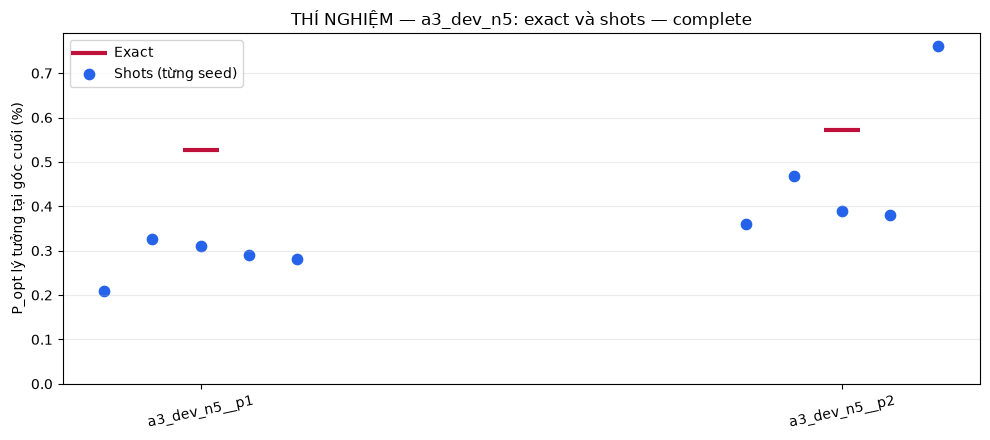

In [9]:
completed = results[results['status'].eq('completed')]
if completed.empty:
    print('Chưa có lượt hoàn tất để vẽ.')
else:
    groups = list(dict.fromkeys(results['group']))
    fig, ax = plt.subplots(figsize=(10, 4.5))
    for i, group in enumerate(groups):
        values = completed[completed['group'].eq(group)]
        exact = values[values['mode'].eq('exact')]
        shots = values[values['mode'].eq('shots')]
        if not exact.empty:
            ax.scatter(i, 100*exact.iloc[0]['p_opt'], marker='_', s=650,
                       color='#be123c', linewidths=3, label='Exact' if i == 0 else None)
        if not shots.empty:
            offsets = np.linspace(-.15, .15, len(shots)) if len(shots)>1 else [0]
            ax.scatter(i+np.asarray(offsets), 100*shots['p_opt'], s=55,
                       color='#2563eb', label='Shots (từng seed)' if i == 0 else None)
    ax.set_xticks(range(len(groups)), groups, rotation=12)
    ax.set_ylabel('P_opt lý tưởng tại góc cuối (%)')
    label = 'KIỂM THỬ PHẦN MỀM' if summary['software_validation'] else 'THÍ NGHIỆM'
    ax.set_title(label+' — a3_dev_n5: exact và shots — '+summary['status'])
    ax.set_ylim(bottom=0)
    ax.grid(axis='y', alpha=.25)
    ax.legend()
    fig.tight_layout()
    fig.savefig(CAMPAIGN_DIR/'endpoint_popt.png', dpi=160)
    plt.show()


## 8. Audit và xuất dữ liệu

Cell cuối có thể mất thêm thời gian vì đánh giá lại góc cuối ở 25 qubit. Nó kiểm checksum, nfev, lịch sử, counts và tính lại exact tại góc cuối; sau đó xuất ZIP. **PASS kiểm tra tính nhất quán; `complete=True` xác nhận đủ kế hoạch.** Cả hai đều không chứng minh QAOA đã tốt hơn. Nếu chưa đủ, ZIP vẫn có nhãn partial để giữ dữ liệu.

Lưu notebook có output, gửi kèm ZIP được in bên dưới. Không loại seed kém. Chỉ kết luận tác động của shots sau khi xem đủ từng nhóm; cả hai yếu thì bước sau là khởi tạo/multistart/INTERP. Hướng dẫn và giới hạn suy luận nằm trong `docs/notebook22_shot_noise_vi.md`.


In [10]:
RESULT_ZIP = export_campaign(ROOT, CAMPAIGN_DIR)
audit = load_json(CAMPAIGN_DIR/'audit.json')
print('audit:', audit['status'], '| complete:', audit['complete'])
print('coverage:', audit['coverage'])
print('Gửi file ZIP:', RESULT_ZIP)
if not audit['complete']:
    print('Dữ liệu chưa đủ; resume đúng CAMPAIGN_DIR trước khi kết luận.')


audit: PASS | complete: True
coverage: {'planned': 12, 'completed': 12, 'pending': 0, 'failed': 0}
Gửi file ZIP: C:\Users\Khiem\quang-tum-com-pu-ting\nt409-task-placement\data\reference_results\phase4n_shot_noise\noise_20261023T081327958984Z.zip
